### Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import os
import math
import matplotlib.colors as mcolors
import matplotlib.tri as tri
import torch
import gpytorch
from pyproj import Proj, transform
from matplotlib import rcParams as rc
import matplotlib
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from pickle import dump, load
import linear_operator
import random
from shapely.geometry import Polygon
import geopandas as gpd

#import user models
#from pylib_gp_twoscale import VelGPModel, Genevarikernel
from pylib_gp_twoscale import VelGPModel, Genevarikernel

configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Arial'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 16,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
norm = mcolors.Normalize(vmin=150., vmax=2000.)  
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

### Define Variables

In [3]:
dir_out = '../Data/Vel_data/'
dir_model = './'
cn_x = ['vs_depth','Z_2.5','surf_elevation','easting','northing'] #output
cn_y = 'diff'   
crs_grid = []

#create x,y,z grid
points_xy = [(-117.8869, 33.7068)]
points_z = np.linspace(0, 70, 71)

for x, y in points_xy:
    for z in points_z:
        crs_grid.append([x, y, z])

#wite geometry for ucvm query
with open(dir_out+'Point_input/'+'ucvm_input_1.txt', "w", encoding="utf-8") as file:
    for i in crs_grid:
        file.write(" ".join(map(str, i)) + "\n") 

In [4]:
df_ucvm = pd.read_csv(dir_out+'Point_input/'+'ucvm_output_1.txt', sep=r'\s+', 
                      header=None,
                      names=['long','lat','vs_depth','site_elevation','vs30',
                             'cvm','cvm_vp','cvm_vs','cvm_dens',
                             'gtl','gtl_vp','gtl_vs','gtl_dens',
                             'alg','vp','vs','dens'])

# get the UTM coordinate
def longlat_to_utm(lon, lat):
    utm_zone = int((lon + 180) / 6) + 1
    proj = Proj(proj='utm', zone=utm_zone, ellps='WGS84')
    easting, northing = proj(lon, lat)
    return easting, northing

df_ucvm[['easting', 'northing']] = df_ucvm.apply(lambda row: pd.Series(longlat_to_utm(row['long'], row['lat'])), axis=1)

df_ucvm['distance'] = np.linalg.norm((df_ucvm[['easting','northing']] - df_ucvm.loc[0,['easting','northing']]).values.astype(float), 
                                     axis=1)
df_ucvm['Z_2.5'] = 3680
df_ucvm = df_ucvm.rename(columns={'site_elevation': 'surf_elevation'})
df_ucvm['basin_idnum'] = 1
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,gtl_dens,alg,vp,vs,dens,easting,northing,distance,Z_2.5,basin_idnum
0,-117.8869,33.7068,0.0,11.451,227.252,cvms5,1579.720,871.215,2041.549,none,...,0.0,crust,1579.720,871.215,2041.549,417815.112553,3.730000e+06,0.0,3680,1
1,-117.8869,33.7068,1.0,11.451,227.252,cvms5,1580.827,871.814,2041.858,none,...,0.0,crust,1580.827,871.814,2041.858,417815.112553,3.730000e+06,0.0,3680,1
2,-117.8869,33.7068,2.0,11.451,227.252,cvms5,1581.933,872.413,2042.166,none,...,0.0,crust,1581.933,872.413,2042.166,417815.112553,3.730000e+06,0.0,3680,1
3,-117.8869,33.7068,3.0,11.451,227.252,cvms5,1583.040,873.013,2042.474,none,...,0.0,crust,1583.040,873.013,2042.474,417815.112553,3.730000e+06,0.0,3680,1
4,-117.8869,33.7068,4.0,11.451,227.252,cvms5,1584.146,873.612,2042.782,none,...,0.0,crust,1584.146,873.612,2042.782,417815.112553,3.730000e+06,0.0,3680,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,-117.8869,33.7068,66.0,11.451,227.252,cvms5,1652.749,910.760,2061.418,none,...,0.0,crust,1652.749,910.760,2061.418,417815.112553,3.730000e+06,0.0,3680,1
67,-117.8869,33.7068,67.0,11.451,227.252,cvms5,1653.856,911.360,2061.712,none,...,0.0,crust,1653.856,911.360,2061.712,417815.112553,3.730000e+06,0.0,3680,1
68,-117.8869,33.7068,68.0,11.451,227.252,cvms5,1654.962,911.959,2062.005,none,...,0.0,crust,1654.962,911.959,2062.005,417815.112553,3.730000e+06,0.0,3680,1
69,-117.8869,33.7068,69.0,11.451,227.252,cvms5,1656.069,912.558,2062.298,none,...,0.0,crust,1656.069,912.558,2062.298,417815.112553,3.730000e+06,0.0,3680,1


In [5]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure

,velocity_metadata_id,vs_depth,vs_value,vs_top_depth,vs_bottom_depth,test_id,velocity_name,velocity_method,velocity_date,velocity_quality,...,terrain_class,site_easting,site_northing,test_easting,test_northing,vs_model,surf_elevation,Z_2.5,diff,basin_idnum
0,610,1.00,155.0,0.5,1.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,938.187,251.052,2380.0,-1.800524,2
1,610,2.00,170.2,1.5,2.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.068,251.052,2380.0,-1.707914,2
2,610,3.00,196.5,2.5,3.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.949,251.052,2380.0,-1.565163,2
3,610,4.00,191.9,3.5,4.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,940.830,251.052,2380.0,-1.589788,2
4,610,5.00,202.0,4.5,5.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,941.711,251.052,2380.0,-1.539431,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11026,2479,12.60,354.0,9.3,15.9,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,894.882,54.938,3620.0,-0.927395,1
11027,2479,21.15,387.0,15.9,26.4,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,899.010,54.938,3620.0,-0.842869,1
11028,2479,34.80,445.0,26.4,43.2,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,905.600,54.938,3620.0,-0.710523,1
11029,2479,56.60,540.0,43.2,70.0,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,916.125,54.938,3620.0,-0.528584,1


In [6]:
df_measure = df_measure[['vs_depth','Z_2.5','surf_elevation','site_easting','site_northing','diff',  'velocity_metadata_id','vs30','basin_idnum']]
df_measure = df_measure.rename(columns={'site_easting': 'easting', 'site_northing': 'northing'})
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2
...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1


In [7]:
df_sonic = pd.read_csv(dir_out+'Training_data/df_sonic.txt', encoding='utf-8')
df_sonic = df_sonic.rename(columns={'X': 'easting', 'Y': 'northing',
                                       'depth': 'vs_depth'})
df_sonic = df_sonic[['vs_depth','Z_2.5','surf_elevation','easting','northing','diff',  'velocity_metadata_id']]

df_sonic['basin_idnum'] = 1
df_sonic

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,basin_idnum
0,67.124000,4400.0,23.596,387402.0000,3753149.500,0.010634,-29,1
1,77.124000,4400.0,23.596,387402.0000,3753149.500,0.018006,-29,1
2,87.124000,4400.0,23.596,387402.0000,3753149.500,0.028627,-29,1
3,97.124000,4400.0,23.596,387402.0000,3753149.500,0.040313,-29,1
4,107.124000,4400.0,23.596,387402.0000,3753149.500,0.051009,-29,1
...,...,...,...,...,...,...,...,...
3177,1956.730197,2500.0,83.353,387298.0938,3767711.984,-0.116894,-28,1
3178,1966.730197,2500.0,83.353,387298.0938,3767711.984,-0.056673,-28,1
3179,1976.730197,2500.0,83.353,387298.0938,3767711.984,-0.040450,-28,1
3180,1986.730197,2500.0,83.353,387298.0938,3767711.984,-0.050204,-28,1


In [8]:
df_veldata = pd.concat([df_measure.reset_index(drop=True), df_sonic.reset_index(drop=True)], ignore_index=True, sort=False)
df_veldata

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2
1,2.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2
2,3.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2
3,4.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2
4,5.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2
...,...,...,...,...,...,...,...,...,...
14208,1956.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.116894,-28,NaN,1
14209,1966.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.056673,-28,NaN,1
14210,1976.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.040450,-28,NaN,1
14211,1986.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.050204,-28,NaN,1


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#read model
scaler_input = load(open(dir_model+'ucvm_la_basin_adj_scaler_frozen.pkl', 'rb'))
model_state = torch.load(dir_model+'ucvm_la_basin_adj_model_frozen_newloss.pth', weights_only=True)

#get training input/output
X_train = scaler_input.transform(df_veldata.loc[:,cn_x].values)
Y_train = df_veldata.loc[:,cn_y].values
#convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float64)
Y_train = torch.tensor(Y_train, dtype=torch.float64)

basin_col = torch.tensor(
    df_veldata['basin_idnum'].to_numpy(),
    dtype=X_train.dtype,
    device=X_train.device
).unsqueeze(1)

X_train = torch.cat([X_train, basin_col], dim=1)
print(X_train)

#define likelihood and model
likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device).double()
model = VelGPModel(X_train, Y_train, likelihood).to(device).double()
model.load_state_dict(model_state)

tensor([[-0.8257, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.8097, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.7936, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        ...,
        [30.8894, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.0499, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.2105, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000]],
       dtype=torch.float64)


<All keys matched successfully>

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#read model
scaler_input = load(open(dir_model+'ucvm_la_basin_adj_scaler_frozen.pkl', 'rb'))
model_state = torch.load(dir_model+'ucvm_la_basin_adj_model_frozen_newloss.pth', weights_only=True)

#get training input/output
X_train = scaler_input.transform(df_veldata.loc[:,cn_x].values)
Y_train = df_veldata.loc[:,cn_y].values
#convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float64)
Y_train = torch.tensor(Y_train, dtype=torch.float64)

basin_col = torch.tensor(
    df_veldata['basin_idnum'].to_numpy(),
    dtype=X_train.dtype,
    device=X_train.device
).unsqueeze(1)

X_train = torch.cat([X_train, basin_col], dim=1)
print(X_train)

#define likelihood and model
likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device).double()
model = VelGPModel(X_train, Y_train, likelihood).to(device).double()
model.load_state_dict(model_state)

tensor([[-0.8257, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.8097, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.7936, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        ...,
        [30.8894, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.0499, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.2105, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000]],
       dtype=torch.float64)


<All keys matched successfully>

In [11]:
X_train_cross = torch.tensor(scaler_input.transform(df_ucvm.loc[:,cn_x].values), dtype=torch.float64)
Y_train_cross = df_ucvm['cvm_vs'].values
Y_train_cross

basin_col = torch.tensor(
    df_ucvm['basin_idnum'].to_numpy(),
    dtype=X_train_cross.dtype,
    device=X_train_cross.device
).unsqueeze(1)

X_train_cross = torch.cat([X_train_cross, basin_col], dim=1)
print(X_train_cross)


X_train_cross.max(axis=0)
X_train.max(axis=0)


df_veldata.loc[:,cn_x].values.max(axis=0)
df_veldata.loc[df_veldata.vs_depth > 380,:].velocity_metadata_id.unique()

tensor([[-0.8418,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.8257,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.8097,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.7936,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.7776,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.7615,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.7455,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.7294,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.7134,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.6973,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.6813,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.6652,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.6492,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.6331,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.6171,  0.7389, -1.0219,  1.2229, -1.4643,  1.0000],
        [-0.6010,  0.7389, -1.0219,  1.2

array([-29, -30, -31, -32, -33,  -1,  -2,  -3,  -4,  -5,  -6,  -7,  -8,
        -9, -10, -11, -12, -13, -14, -15, -16, -17, -18, -19, -22, -23,
       -24, -25, -26, -27, -28])

In [12]:
#train GP model
model.eval()
likelihood.eval()

with torch.no_grad():
    observed_pred = likelihood(model(X_train_cross.to(device).double()))
    predict_value = observed_pred.mean.detach().cpu()
    std = observed_pred.stddev.detach().cpu()

    #samples = model(X_train_cross.to(device).double()).rsample(torch.Size([3]))
    #fstd = model(X_train_cross.to(device).double()).stddev



lower = predict_value - 1.96 * std
upper = predict_value + 1.96 * std

In [13]:
df_ucvm['predict_diff'] = predict_value
#df_ucvm['predict_vs'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff"].to_numpy()*df_ucvm['factor'])
df_ucvm['predict_vs'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff"].to_numpy())

df_ucvm['predict_diff_low'] = lower
df_ucvm['predict_vs_low'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff_low"].to_numpy())
df_ucvm['predict_diff_upper'] = upper
df_ucvm['predict_vs_upper'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff_upper"].to_numpy())

In [14]:
df_ucvm = df_ucvm[df_ucvm['lat'] == 33.7068]
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,northing,distance,Z_2.5,basin_idnum,predict_diff,predict_vs,predict_diff_low,predict_vs_low,predict_diff_upper,predict_vs_upper
0,-117.8869,33.7068,0.0,11.451,227.252,cvms5,1579.720,871.215,2041.549,none,...,3.730000e+06,0.0,3680,1,-1.931121,126.313617,-2.406837,78.496291,-1.455404,203.259666
1,-117.8869,33.7068,1.0,11.451,227.252,cvms5,1580.827,871.814,2041.858,none,...,3.730000e+06,0.0,3680,1,-1.878540,133.224546,-2.351413,83.026804,-1.405668,213.771682
2,-117.8869,33.7068,2.0,11.451,227.252,cvms5,1581.933,872.413,2042.166,none,...,3.730000e+06,0.0,3680,1,-1.826517,140.435199,-2.297834,87.656776,-1.355200,224.991677
3,-117.8869,33.7068,3.0,11.451,227.252,cvms5,1583.040,873.013,2042.474,none,...,3.730000e+06,0.0,3680,1,-1.775252,147.923949,-2.245321,92.446423,-1.305183,236.693795
4,-117.8869,33.7068,4.0,11.451,227.252,cvms5,1584.146,873.612,2042.782,none,...,3.730000e+06,0.0,3680,1,-1.724929,155.665139,-2.194333,97.349104,-1.255526,248.914826
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,-117.8869,33.7068,66.0,11.451,227.252,cvms5,1652.749,910.760,2061.418,none,...,3.730000e+06,0.0,3680,1,-0.577761,511.075802,-1.101075,302.839914,-0.054448,862.496863
67,-117.8869,33.7068,67.0,11.451,227.252,cvms5,1653.856,911.360,2061.712,none,...,3.730000e+06,0.0,3680,1,-0.574206,513.234157,-1.100166,303.315114,-0.048246,868.434469
68,-117.8869,33.7068,68.0,11.451,227.252,cvms5,1654.962,911.959,2062.005,none,...,3.730000e+06,0.0,3680,1,-0.570693,515.378601,-1.099327,303.769113,-0.042059,874.397991
69,-117.8869,33.7068,69.0,11.451,227.252,cvms5,1656.069,912.558,2062.298,none,...,3.730000e+06,0.0,3680,1,-0.567190,517.527218,-1.098583,304.194959,-0.035796,880.469623


In [15]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure = df_measure[['vs_depth','Z_2.5','surf_elevation','site_easting','site_northing','diff',  'velocity_metadata_id','vs30','basin_idnum','vs_value']]
df_measure = df_measure.rename(columns={'site_easting': 'easting', 'site_northing': 'northing', 'diff_smooth': 'diff'})
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_value
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2,155.0
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2,170.2
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2,196.5
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2,191.9
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2,202.0
...,...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1,354.0
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1,387.0
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1,445.0
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1,540.0


In [16]:
def get_vs0(vs30 = 228.2):
    p1 = -2.1688e-4
    p2 = 0.5182
    p3 = 69.452
    return p1 * vs30**2 + p2 * vs30 + p3

def get_k(vs30 = 228.2):
    r1 = -59.67
    r2 = -0.2722
    r3 = 11.132
    return np.exp(r1 * (vs30**r2) + r3)

def get_n(vs30 = 228.2):
    s1 = 4.110
    s2 = -1.0521e-4
    s3 = -10.827
    s4 = -7.6187e-3
    return s1 * np.exp(s2 * vs30) + s3 * np.exp(s4 * vs30)

def get_vs_z(z, vs30):
    z = np.asarray(z)
    vs0 = get_vs0(vs30)
    k = get_k(vs30)
    n = get_n(vs30)
    vs = np.where(
        z <= 2.5,
        vs0,
        vs0 * (1.0 + k * (z - 2.5))**(1.0 / n)
    )
    return vs

vs = get_vs_z(df_ucvm['vs_depth'], 228.2)
df_ucvm['shi'] = vs
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,distance,Z_2.5,basin_idnum,predict_diff,predict_vs,predict_diff_low,predict_vs_low,predict_diff_upper,predict_vs_upper,shi
0,-117.8869,33.7068,0.0,11.451,227.252,cvms5,1579.720,871.215,2041.549,none,...,0.0,3680,1,-1.931121,126.313617,-2.406837,78.496291,-1.455404,203.259666,176.411162
1,-117.8869,33.7068,1.0,11.451,227.252,cvms5,1580.827,871.814,2041.858,none,...,0.0,3680,1,-1.878540,133.224546,-2.351413,83.026804,-1.405668,213.771682,176.411162
2,-117.8869,33.7068,2.0,11.451,227.252,cvms5,1581.933,872.413,2042.166,none,...,0.0,3680,1,-1.826517,140.435199,-2.297834,87.656776,-1.355200,224.991677,176.411162
3,-117.8869,33.7068,3.0,11.451,227.252,cvms5,1583.040,873.013,2042.474,none,...,0.0,3680,1,-1.775252,147.923949,-2.245321,92.446423,-1.305183,236.693795,179.885775
4,-117.8869,33.7068,4.0,11.451,227.252,cvms5,1584.146,873.612,2042.782,none,...,0.0,3680,1,-1.724929,155.665139,-2.194333,97.349104,-1.255526,248.914826,186.620533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,-117.8869,33.7068,66.0,11.451,227.252,cvms5,1652.749,910.760,2061.418,none,...,0.0,3680,1,-0.577761,511.075802,-1.101075,302.839914,-0.054448,862.496863,423.229818
67,-117.8869,33.7068,67.0,11.451,227.252,cvms5,1653.856,911.360,2061.712,none,...,0.0,3680,1,-0.574206,513.234157,-1.100166,303.315114,-0.048246,868.434469,425.881395
68,-117.8869,33.7068,68.0,11.451,227.252,cvms5,1654.962,911.959,2062.005,none,...,0.0,3680,1,-0.570693,515.378601,-1.099327,303.769113,-0.042059,874.397991,428.514782
69,-117.8869,33.7068,69.0,11.451,227.252,cvms5,1656.069,912.558,2062.298,none,...,0.0,3680,1,-0.567190,517.527218,-1.098583,304.194959,-0.035796,880.469623,431.130336


In [17]:
df_ucvm = df_ucvm[df_ucvm['vs_depth'] <= 100]
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,distance,Z_2.5,basin_idnum,predict_diff,predict_vs,predict_diff_low,predict_vs_low,predict_diff_upper,predict_vs_upper,shi
0,-117.8869,33.7068,0.0,11.451,227.252,cvms5,1579.720,871.215,2041.549,none,...,0.0,3680,1,-1.931121,126.313617,-2.406837,78.496291,-1.455404,203.259666,176.411162
1,-117.8869,33.7068,1.0,11.451,227.252,cvms5,1580.827,871.814,2041.858,none,...,0.0,3680,1,-1.878540,133.224546,-2.351413,83.026804,-1.405668,213.771682,176.411162
2,-117.8869,33.7068,2.0,11.451,227.252,cvms5,1581.933,872.413,2042.166,none,...,0.0,3680,1,-1.826517,140.435199,-2.297834,87.656776,-1.355200,224.991677,176.411162
3,-117.8869,33.7068,3.0,11.451,227.252,cvms5,1583.040,873.013,2042.474,none,...,0.0,3680,1,-1.775252,147.923949,-2.245321,92.446423,-1.305183,236.693795,179.885775
4,-117.8869,33.7068,4.0,11.451,227.252,cvms5,1584.146,873.612,2042.782,none,...,0.0,3680,1,-1.724929,155.665139,-2.194333,97.349104,-1.255526,248.914826,186.620533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,-117.8869,33.7068,66.0,11.451,227.252,cvms5,1652.749,910.760,2061.418,none,...,0.0,3680,1,-0.577761,511.075802,-1.101075,302.839914,-0.054448,862.496863,423.229818
67,-117.8869,33.7068,67.0,11.451,227.252,cvms5,1653.856,911.360,2061.712,none,...,0.0,3680,1,-0.574206,513.234157,-1.100166,303.315114,-0.048246,868.434469,425.881395
68,-117.8869,33.7068,68.0,11.451,227.252,cvms5,1654.962,911.959,2062.005,none,...,0.0,3680,1,-0.570693,515.378601,-1.099327,303.769113,-0.042059,874.397991,428.514782
69,-117.8869,33.7068,69.0,11.451,227.252,cvms5,1656.069,912.558,2062.298,none,...,0.0,3680,1,-0.567190,517.527218,-1.098583,304.194959,-0.035796,880.469623,431.130336


In [18]:
from pyproj import Transformer

target_lat = 33.706
target_lon = -117.885

transformer = Transformer.from_crs("EPSG:4326", "EPSG:32611", always_xy=True)
target_easting, target_northing = transformer.transform(target_lon, target_lat)

dist = np.sqrt(
    (df_measure["easting"].to_numpy() - target_easting)**2 +
    (df_measure["northing"].to_numpy() - target_northing)**2
)

df_measure["dist_m"] = dist

row_nearest = df_measure.loc[df_measure["dist_m"].idxmin()]
row_nearest

vs_depth                5.000000e-01
Z_2.5                   3.680000e+03
surf_elevation          1.144400e+01
easting                 4.177777e+05
northing                3.729956e+06
diff                   -2.176121e+00
velocity_metadata_id    4.470000e+02
vs30                    2.223470e+02
basin_idnum             1.000000e+00
vs_value                9.900000e+01
dist_m                  2.177119e+02
Name: 8920, dtype: float64

In [19]:
df_close = df_measure[df_measure['velocity_metadata_id'] == 447]
df_close

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_value,dist_m
8920,0.50,3680.0,11.444,417777.664087,3.729956e+06,-2.176121,447,222.347,1,99.0,217.711885
8921,1.75,3680.0,11.444,417777.664087,3.729956e+06,-1.881746,447,222.347,1,133.0,217.711885
8922,3.75,3680.0,11.444,417777.664087,3.729956e+06,-1.846204,447,222.347,1,138.0,217.711885
8923,7.00,3680.0,11.444,417777.664087,3.729956e+06,-1.634005,447,222.347,1,171.0,217.711885
8924,12.00,3680.0,11.444,417777.664087,3.729956e+06,-1.277803,447,222.347,1,245.0,217.711885
8925,19.50,3680.0,11.444,417777.664087,3.729956e+06,-1.077019,447,222.347,1,301.0,217.711885
8926,30.00,3680.0,11.444,417777.664087,3.729956e+06,-0.962234,447,222.347,1,340.0,217.711885
8927,43.50,3680.0,11.444,417777.664087,3.729956e+06,-0.791361,447,222.347,1,407.0,217.711885
8928,60.50,3680.0,11.444,417777.664087,3.729956e+06,-0.643869,447,222.347,1,477.0,217.711885


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

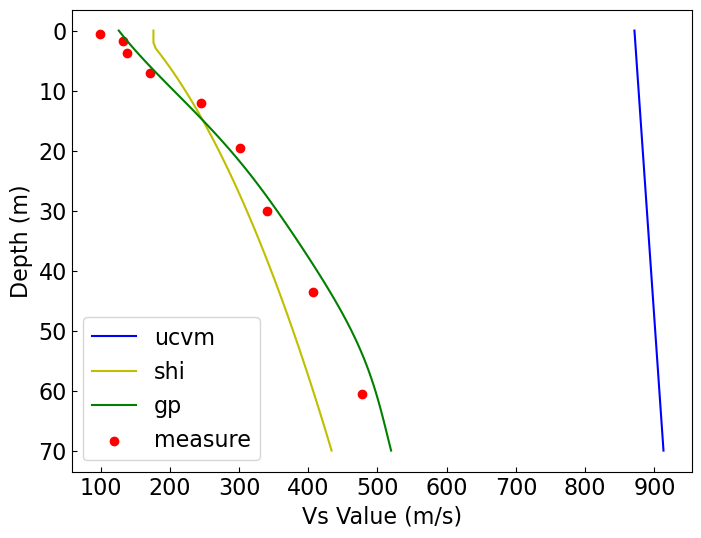

In [20]:
plt.figure(figsize=(8, 6))
plt.plot(df_ucvm['cvm_vs'], df_ucvm['vs_depth'], color='b', label="ucvm")
plt.plot(df_ucvm['shi'], df_ucvm['vs_depth'], color='y', label="shi")
plt.plot(df_ucvm['predict_vs'], df_ucvm['vs_depth'], color='g', label="gp")
plt.scatter(df_close['vs_value'], df_close['vs_depth'], color='r', label="measure")
plt.gca().invert_yaxis()
plt.xlabel("Vs Value (m/s)")
plt.ylabel("Depth (m)")
plt.legend()
plt.grid()
plt.show()

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

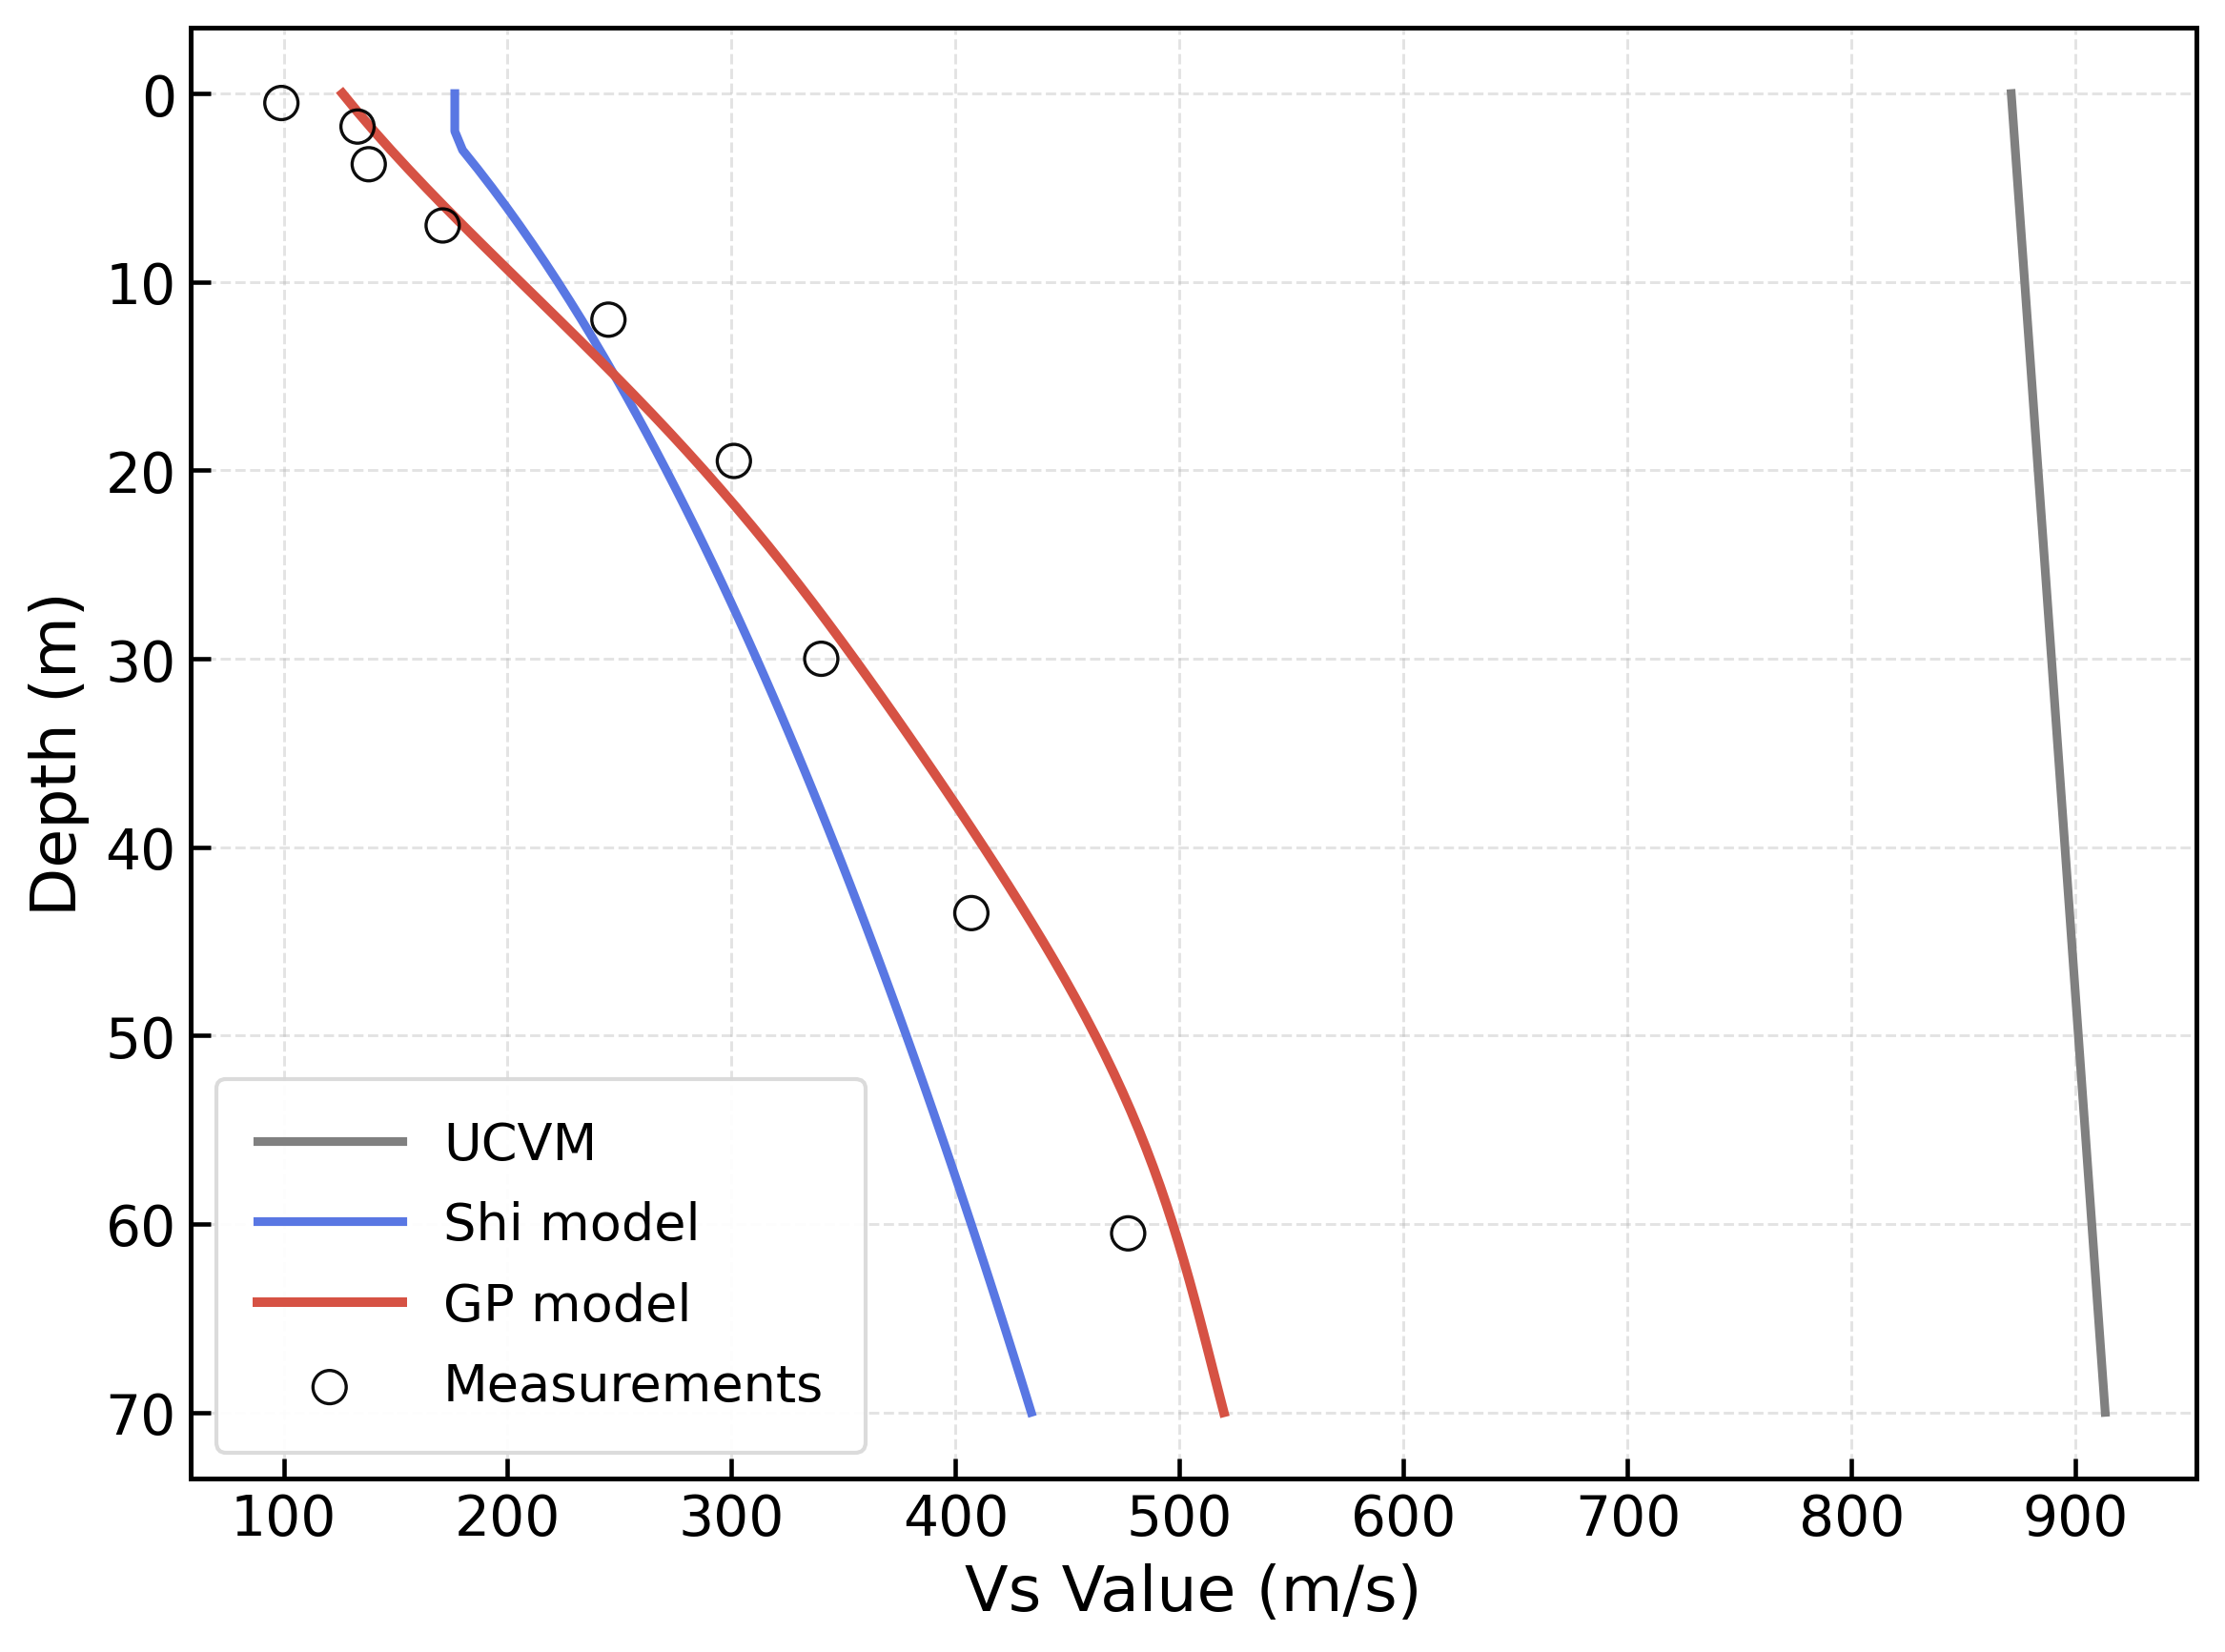

In [21]:
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)


plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 14
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)


ax.plot(
    df_ucvm['cvm_vs'], df_ucvm['vs_depth'],
    color='gray', lw=2.2, label="UCVM"
)

ax.plot(
    df_ucvm['shi'], df_ucvm['vs_depth'],
    color=blue_color, lw=2.2, label="Shi model"
)

ax.plot(
    df_ucvm['predict_vs'], df_ucvm['vs_depth'],
    color=red_color, lw=2.4, label="GP model"
)

ax.scatter(
    df_close['vs_value'], df_close['vs_depth'],
    s=70, color="black",
    linewidth=0.8, alpha=0.95, label="Measurements",
    facecolors="none",
    edgecolors="black",
    zorder=5
)

ax.invert_yaxis()
ax.set_xlabel("Vs Value (m/s)", fontsize=16)
ax.set_ylabel("Depth (m)", fontsize=16)

ax.grid(
    True, which="major",
    linestyle="--", linewidth=0.7, alpha=0.35
)


ax.tick_params(axis="both", which="major", labelsize=14, length=5, width=1.1)

leg = ax.legend(
    loc="lower left",
    fontsize=13,
    frameon=True,
    handlelength=2.8,
    borderpad=0.8,
    labelspacing=0.6
)
leg.get_frame().set_edgecolor("0.85")
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(0.95)

plt.tight_layout()
plt.show()

In [22]:
df_ucvm.to_csv(dir_out+'Point_input/'+'df_ucvm_1.txt', index=False,
                  encoding='utf-8',
                  lineterminator='\n')